# Actividad: Dataset - Notebook

* **Fecha**: 4 de octubre de 2026
* **Estudiante**: Alejandro Gil Ruiz
* **Matrícula**: A01639802

## Introducción
---
Este trabajo ejecuta un flujo completo de aprendizaje automático sobre el conjunto [Student Retention & Academic Performance Data](https://www.kaggle.com/datasets/razanihababdellatif/student-retention-and-academic-performance-data) para predecir la deserción (`Target_Dropout_Next_Sem`). Documenta la exploración de los datos, la limpieza, un modelo base, la evaluación y el registro del experimento en MLflow, y cierra con una reflexión sobre prácticas de MLOps.


### Diccionario de variables

| Variable | Tipo | Confirmado |
| --- | --- | --- |
| `Student_ID` | str | 20,000 identificadores únicos. Junto con `Semester`, identifica cada fila |
| `Age` | int64 | Entero de 17 a 37 |
| `Gender` | str | 8 etiquetas; algunas nombran el mismo valor (`Female`/`female`/`F`, `Male`/`male`/`M`) |
| `First_Generation` | int64 | Solo 0 o 1 |
| `Family_Income` | float64 | Ingreso del hogar (listado de Kaggle). 3,604 valores faltantes |
| `Household_Size` | int64 | Entero de 1 a 6 |
| `Housing_Status` | str | `On-Campus`, `Off-Campus`, `With Parents` |
| `Scholarship` | int64 | Solo 0 o 1 |
| `Tuition_Base` | int64 | Solo 15,000, 25,000 o 45,000 |
| `Semester` | int64 | Semestre 1 a 8 (listado de Kaggle) |
| `Course_Load` | int64 | Solo 9, 12, 15, 18 o 21 |
| `Work_Hours` | float64 | Numérico de 0 a 40 |
| `Emergency_Expense` | float64 | Numérico de 0 a 3,998 |
| `Sem_GPA` | float64 | Numérico de 0.44 a 3.96 |
| `Attendance` | float64 | Numérico de -2 a 105 |
| `LMS_Logins` | float64 | Numérico. 867 valores faltantes (listado de Kaggle) |
| `Advising_Visits` | int64 | Entero de 0 a 3 |
| `Failed_Courses` | int64 | Entero de 0 a 5 |
| `Financial_Stress` | float64 | Numérico de 1.0 a 18.6 |
| `Target_Dropout_Next_Sem` | int64 | **Objetivo** (listado de Kaggle): 1 si el estudiante deserta el siguiente semestre, 0 en caso contrario |
| `End_of_Semester_Status` | str | `Enrolled`, `Dropped_Out`, `Graduated` |
| `Censored` | int64 | Solo 0 o 1 |


## Paso 1. Cargar y describir el conjunto de datos
---
Conjunto sintético de Kaggle (licencia CC0). Cada fila es un estudiante en un semestre, y el mismo estudiante puede aparecer hasta en 8 semestres. La variable objetivo es `Target_Dropout_Next_Sem`.

Los datos se descargan con `kagglehub` y se cargan como un `DataFrame` de pandas.


In [42]:
import kagglehub
import pandas as pd
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "razanihababdellatif/student-retention-and-academic-performance-data",
    "academic_survival_longitudinal.csv",
)

df.head()

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [43]:
n_rows, n_cols = df.shape
n_students = df["Student_ID"].nunique()

print(f"Filas: {n_rows:,}")
print(f"Columnas: {n_cols}")
print(f"Estudiantes únicos: {n_students:,}")
print(f"Semestres por estudiante: {df.groupby('Student_ID').size().min()} a {df.groupby('Student_ID').size().max()}")


Rows: 79,239
Columns: 22
Unique students: 20,000
Semesters per student: 1 to 8


In [44]:
summary = pd.DataFrame(
    {
        "Tipo": df.dtypes.astype(str),
        "Valores únicos": df.nunique(),
        "Valores faltantes": df.isna().sum(),
    }
)
summary


,Type,Unique values,Missing values
Student_ID,str,20000,0
Age,int64,19,0
Gender,str,8,0
First_Generation,int64,2,0
Family_Income,float64,296,3604
Household_Size,int64,6,0
Housing_Status,str,3,0
Scholarship,int64,2,0
Tuition_Base,int64,3,0
Semester,int64,8,0


## Paso 2. Análisis exploratorio
---
El paso 1 dejó una tabla, `df`: 79,239 filas y 22 columnas. Cada fila es un estudiante en un semestre. Este paso lee esa misma tabla. No copia las filas a otro conjunto y no corrige ningún valor.

Las secciones de abajo se apoyan unas en otras. Primero se agrupan las columnas por tipo. Las estadísticas usan esos grupos, y las gráficas muestran la forma que hay detrás de los números. Los valores se corrigen en el paso 3.


### Separar las variables por tipo
---
Cada columna entra en una lista. Las celdas de abajo toman columnas de esas listas, así que las estadísticas, las gráficas y las comparaciones usan el mismo agrupamiento.

Las columnas continuas son escalas numéricas. Las discretas son enteros con pocos niveles. Las categóricas son etiquetas de texto. Las binarias solo toman 0 o 1.

`Student_ID` queda fuera de todas las listas. El paso 1 ya lo usó, junto con `Semester`, para identificar cada fila. `Target_Dropout_Next_Sem` se guarda aparte. La última sección compara las demás listas contra él.


In [45]:
continuous = [
    "Family_Income",
    "Work_Hours",
    "Emergency_Expense",
    "Sem_GPA",
    "Attendance",
    "LMS_Logins",
    "Financial_Stress",
]
discrete = [
    "Age",
    "Household_Size",
    "Semester",
    "Course_Load",
    "Tuition_Base",
    "Advising_Visits",
    "Failed_Courses",
]
categorical = [
    "Gender",
    "Housing_Status",
    "End_of_Semester_Status",
]
binary = [
    "First_Generation",
    "Scholarship",
    "Censored",
]
target = "Target_Dropout_Next_Sem"

grouped = continuous + discrete + categorical + binary + [target]
left_out = [column for column in df.columns if column not in grouped]
print(f"Columnas agrupadas: {len(grouped)}")
print(f"Fuera: {left_out}")


Grouped columns: 21
Left out: ['Student_ID']


### Estadísticas descriptivas
---
Las listas de arriba deciden el resumen. Las columnas continuas y discretas son numéricas, así que una tabla reporta el conteo, la media, la desviación estándar y los cuartiles. Las categóricas, las binarias y el objetivo no son promedios. Cada uno de sus valores es un conteo y una proporción de las 79,239 filas.

El conteo es donde aparece un valor faltante. `Family_Income` y `LMS_Logins` ya faltaban en el paso 1, así que sus conteos quedan por debajo del total de filas. `Attendance` va de menos de 0 a más de 100, y `Gender` sigue con ocho etiquetas para dos categorías. Las dos se quedan como están. La tabla de frecuencias termina con el objetivo, así que se ve la proporción de deserción.


In [46]:
df[continuous + discrete].describe().T

,count,mean,std,min,25%,50%,75%,max
Family_Income,75635.0,61518.384346,39661.166570,3000.00,35000.00,52000.0,77000.00,488000.00
Work_Hours,79239.0,16.936129,10.724479,0.00,8.30,16.5,24.90,40.00
Emergency_Expense,79239.0,200.496788,724.400513,0.00,0.00,0.0,0.00,3998.00
Sem_GPA,79239.0,2.691463,0.422692,0.44,2.44,2.7,2.96,3.96
Attendance,79239.0,85.081599,6.415864,-2.00,81.20,85.2,89.20,105.00
LMS_Logins,78372.0,66.375670,12.730793,12.00,58.00,66.0,75.00,116.00
Financial_Stress,79239.0,2.578287,1.817880,1.00,1.00,2.1,3.40,18.60
Age,79239.0,19.492005,2.139140,17.00,18.00,19.0,21.00,37.00
Household_Size,79239.0,3.187547,1.332861,1.00,2.00,3.0,4.00,6.00
Semester,79239.0,3.145673,1.946207,1.00,1.00,3.0,4.00,8.00


In [47]:
def frequency_table(columns):
    frames = []
    for column in columns:
        counts = df[column].value_counts(dropna=False)
        frames.append(
            pd.DataFrame(
                {
                    "columna": column,
                    "valor": counts.index.map(str),
                    "conteo": counts.to_numpy(),
                    "proporción": counts.to_numpy() / len(df),
                }
            )
        )
    table = pd.concat(frames, ignore_index=True)
    table["proporción"] = table["proporción"].round(4)
    return table


frequency_table(categorical + binary + [target])


,column,value,count,proportion
0,Gender,Female,38035,0.4800
1,Gender,Male,36556,0.4613
2,Gender,Other,1125,0.0142
3,Gender,female,875,0.0110
4,Gender,male,764,0.0096
5,Gender,M,739,0.0093
6,Gender,F,716,0.0090
7,Gender,Prefer not to say,429,0.0054
8,Housing_Status,On-Campus,31315,0.3952
9,Housing_Status,With Parents,24767,0.3126


### Visualizar cada distribución
---
Las tablas dan un número por columna. Estas gráficas muestran la forma de la que salen esos números, con los mismos grupos.

Un histograma sirve para las continuas, porque toman muchos valores. Una gráfica de barras sirve para las discretas, las categóricas, las binarias y el objetivo, porque cada una toma pocos niveles. El histograma de `Attendance` es la imagen del rango que reportó `describe()`. Las barras de `Gender` son la imagen de las ocho etiquetas de la tabla de frecuencias.


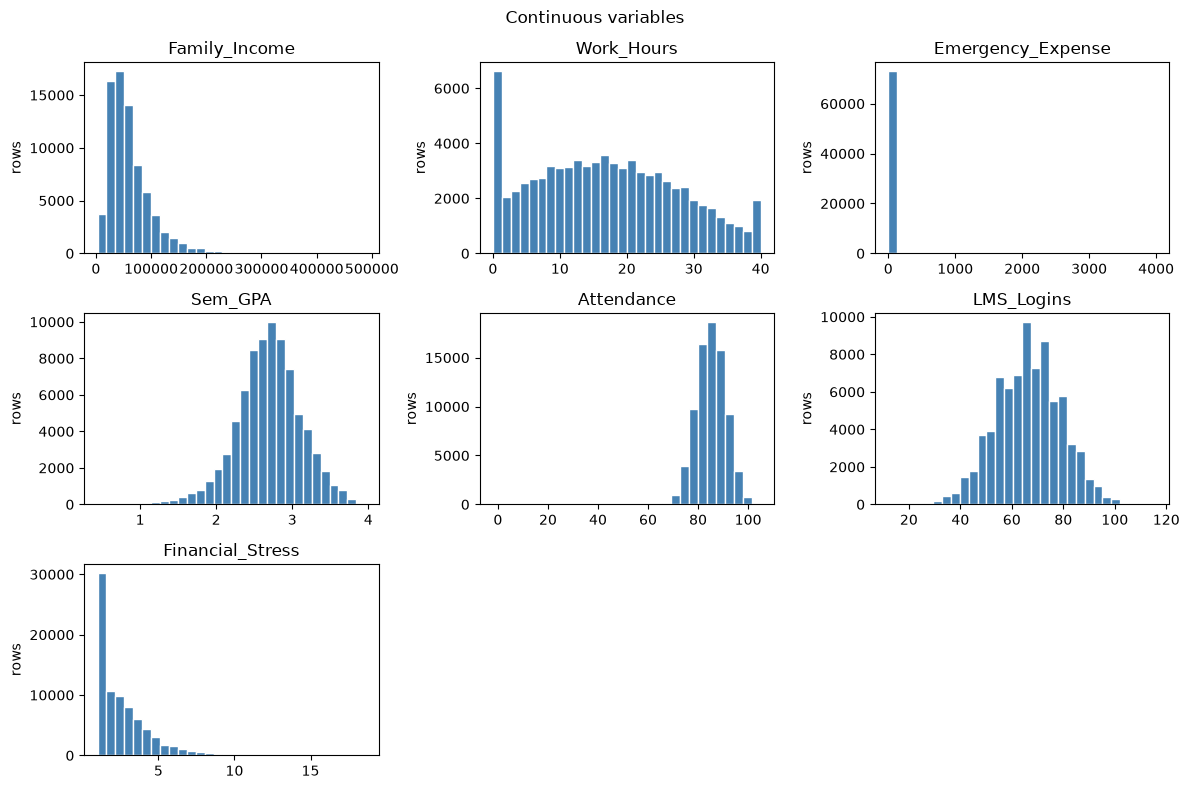

In [48]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(12, 8))
axes = axes.ravel()

for ax, column in zip(axes, continuous):
    ax.hist(df[column].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("filas")

for ax in axes[len(continuous) :]:
    ax.axis("off")

fig.suptitle("Variables continuas")
fig.tight_layout()
plt.show()


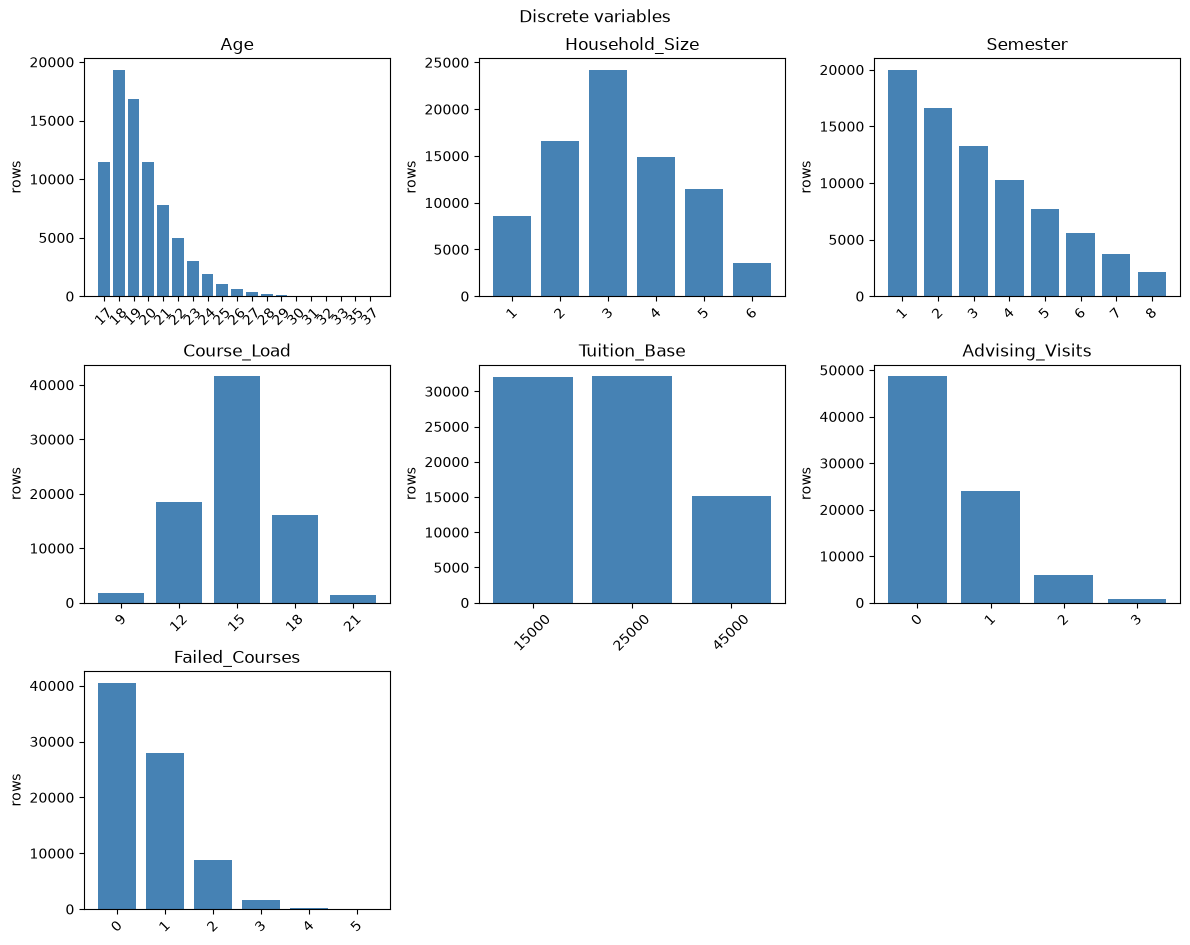

In [49]:
def bar_counts(columns, title):
    ncols = 3
    nrows = (len(columns) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows))
    axes = axes.ravel()

    for ax, column in zip(axes, columns):
        counts = df[column].value_counts(dropna=False).sort_index()
        ax.bar(counts.index.astype(str), counts.to_numpy(), color="steelblue")
        ax.set_title(column)
        ax.tick_params(axis="x", labelrotation=45)
        ax.set_ylabel("filas")

    for ax in axes[len(columns) :]:
        ax.axis("off")

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


bar_counts(discrete, "Variables discretas")


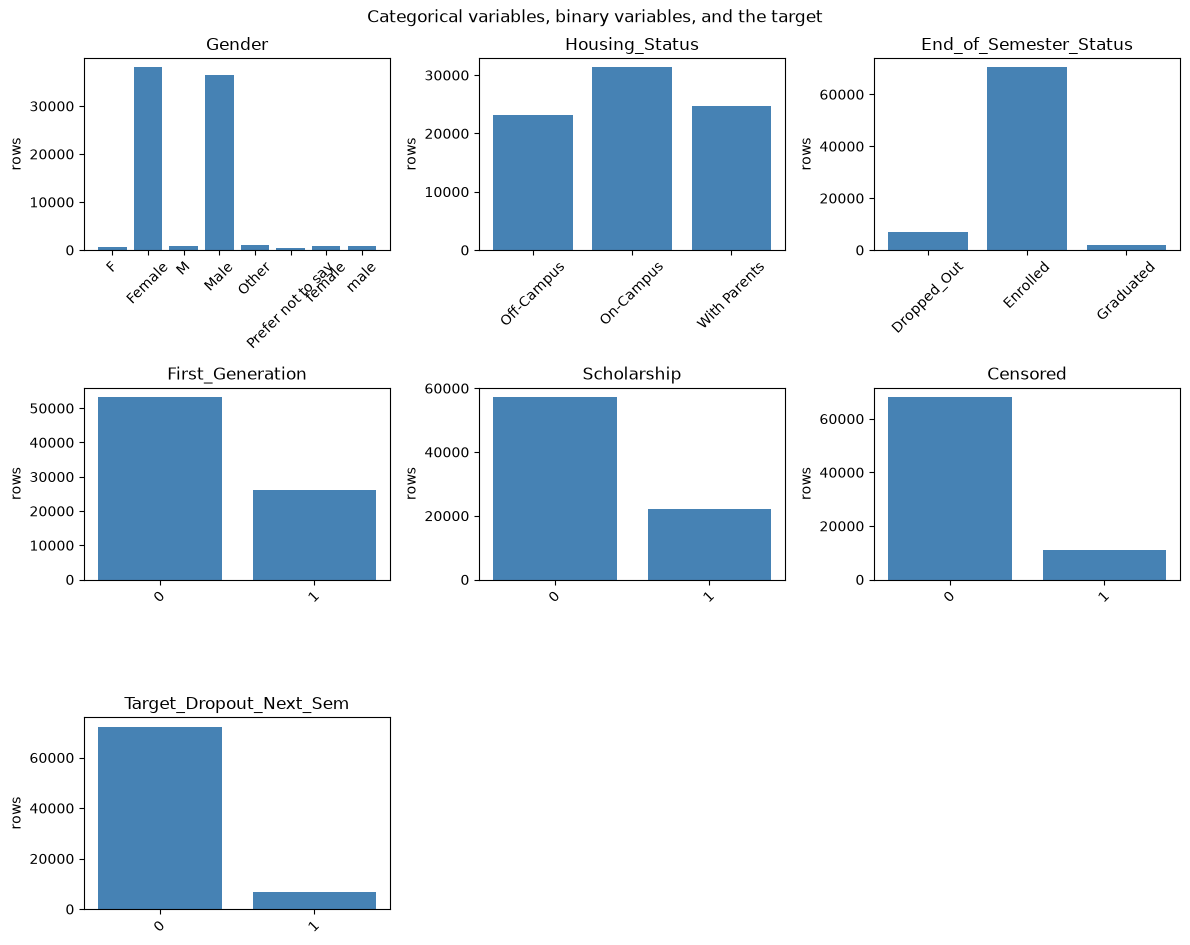

In [50]:
bar_counts(
    categorical + binary + [target],
    "Variables categóricas, binarias y el objetivo",
)


## Paso 3. Limpiar los datos
---
El paso 2 dejó los valores sin cambio. Este paso trata valores faltantes, duplicados, valores atípicos y tipos incorrectos. La decisión queda escrita en cada bloque.


### Valores faltantes
---
`Family_Income` tiene 3,604 valores faltantes y `LMS_Logins` tiene 867. Decisión: rellenar cada columna con su propia mediana. Las filas se quedan en la tabla, y la mediana no se deja arrastrar por unos pocos valores extremos.


In [51]:
df["Family_Income"] = df["Family_Income"].fillna(df["Family_Income"].median())
df["LMS_Logins"] = df["LMS_Logins"].fillna(df["LMS_Logins"].median())
df[["Family_Income", "LMS_Logins"]].isna().sum()


Family_Income    0
LMS_Logins       0
dtype: int64

### Duplicados
---
Decisión: no se elimina ninguna fila. No hay filas completamente duplicadas, y `Student_ID` con `Semester` es único.


In [52]:
print("Filas duplicadas:", df.duplicated().sum())
print("Student_ID + Semester duplicados:", df.duplicated(["Student_ID", "Semester"]).sum())


Duplicated rows: 0
Duplicated Student_ID + Semester: 0


### Valores atípicos
---
`Attendance` incluye -2, 101 y 105. Decisión: recortar la columna a 0–100. La asistencia no puede quedar fuera de ese rango.


In [53]:
df["Attendance"] = df["Attendance"].clip(0, 100)
df["Attendance"].agg(["min", "max"])

min      0.0
max    100.0
Name: Attendance, dtype: float64

### Tipos incorrectos
---
Los tipos de columna ya coinciden con los datos: los enteros son números enteros, las medidas son flotantes y las etiquetas son texto. Decisión: no se cambia ningún tipo.

Los valores incorrectos están en `Gender`. `Female`, `female` y `F` son la misma categoría, y `Male`, `male` y `M` son la misma categoría. Esas etiquetas se unen. `Other` y `Prefer not to say` se quedan.


In [54]:
df["Gender"] = df["Gender"].replace(
    {
        "female": "Female",
        "F": "Female",
        "male": "Male",
        "M": "Male",
    }
)
df["Gender"].value_counts()

Gender
Female               39626
Male                 38059
Other                 1125
Prefer not to say      429
Name: count, dtype: int64

### Matriz de correlación
---
Usa las columnas continuas y discretas ya limpias. `Attendance` ya está recortada, y las dos columnas con faltantes ya están rellenadas. `Gender` es texto, así que no entra en la matriz.


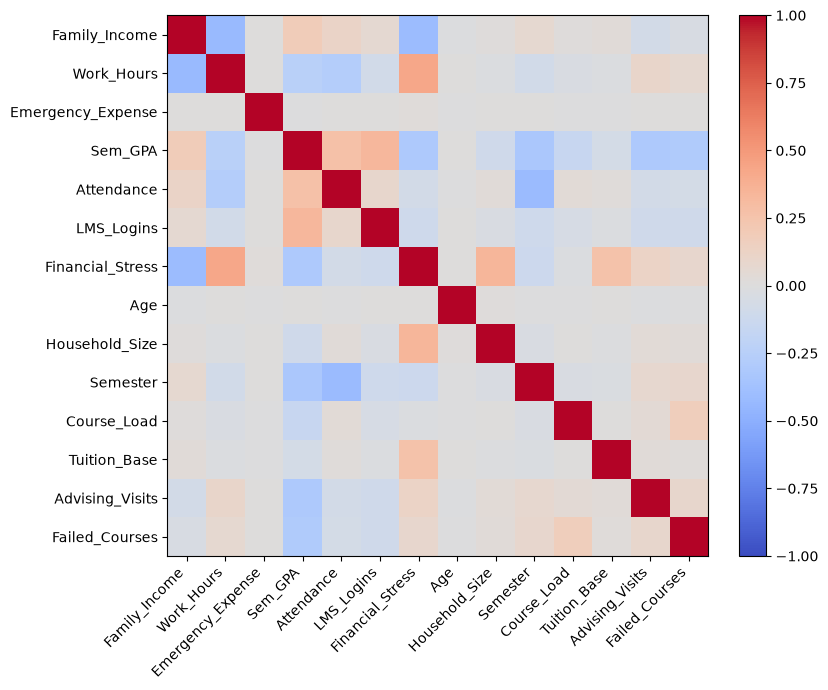

,Family_Income,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Financial_Stress,Age,Household_Size,Semester,Course_Load,Tuition_Base,Advising_Visits,Failed_Courses
Family_Income,1.00,-0.43,0.00,0.18,0.11,0.06,-0.41,-0.01,0.01,0.06,0.02,0.03,-0.08,-0.04
Work_Hours,-0.43,1.00,0.00,-0.24,-0.27,-0.08,0.42,0.00,-0.02,-0.08,-0.03,-0.02,0.10,0.06
Emergency_Expense,0.00,0.00,1.00,-0.00,0.00,0.00,0.02,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
Sem_GPA,0.18,-0.24,-0.00,1.00,0.27,0.33,-0.31,0.00,-0.10,-0.32,-0.15,-0.07,-0.30,-0.30
Attendance,0.11,-0.27,0.00,0.27,1.00,0.09,-0.07,-0.01,0.03,-0.42,0.03,0.02,-0.08,-0.07
LMS_Logins,0.06,-0.08,0.00,0.33,0.09,1.00,-0.10,0.00,-0.03,-0.11,-0.05,-0.02,-0.10,-0.10
Financial_Stress,-0.41,0.42,0.02,-0.31,-0.07,-0.10,1.00,0.01,0.34,-0.12,-0.02,0.26,0.12,0.08
Age,-0.01,0.00,-0.00,0.00,-0.01,0.00,0.01,1.00,0.01,-0.00,-0.01,0.00,-0.01,-0.00
Household_Size,0.01,-0.02,0.00,-0.10,0.03,-0.03,0.34,0.01,1.00,-0.04,0.01,-0.01,0.03,0.03
Semester,0.06,-0.08,0.00,-0.32,-0.42,-0.11,-0.12,-0.00,-0.04,1.00,-0.04,-0.03,0.07,0.08


In [55]:
numeric = continuous + discrete
correlation = df[numeric].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(numeric)), labels=numeric, rotation=45, ha="right")
ax.set_yticks(range(len(numeric)), labels=numeric)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

correlation.round(2)


### Pares por encima de 0.3
---
Ningún par de la matriz es fuerte. La correlación absoluta más alta es de cerca de 0.43. La tabla conserva los pares cuya correlación absoluta es de al menos 0.3.


In [56]:
threshold = 0.3

pairs = correlation.stack().reset_index()
pairs.columns = ["variable_a", "variable_b", "correlación"]
pairs = pairs[pairs["variable_a"] < pairs["variable_b"]]
pairs = pairs[pairs["correlación"].abs() >= threshold]
pairs = pairs.reindex(pairs["correlación"].abs().sort_values(ascending=False).index)
pairs.round(3)


,variable_a,variable_b,correlation
1,Family_Income,Work_Hours,-0.427
85,Financial_Stress,Work_Hours,0.424
65,Attendance,Semester,-0.416
6,Family_Income,Financial_Stress,-0.408
92,Financial_Stress,Household_Size,0.339
73,LMS_Logins,Sem_GPA,0.329
51,Sem_GPA,Semester,-0.325
87,Financial_Stress,Sem_GPA,-0.307
171,Advising_Visits,Sem_GPA,-0.305


## Paso 4. Entrenar un modelo base
---
El objetivo es 0 o 1, así que el modelo base es una regresión logística. Las filas se parten 80/20, y los dos lados conservan la misma proporción de deserciones.

`Student_ID` solo identifica, así que queda fuera. `End_of_Semester_Status` coincide con el objetivo, y `Censored` = 1 no tiene deserciones, así que esas dos también quedan fuera. Las demás columnas son las variables. Las de texto pasan a indicadores 0/1, y un escalador pone los números en un rango comparable antes del ajuste.


In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = continuous + discrete + [
    "First_Generation",
    "Scholarship",
    "Gender",
    "Housing_Status",
]
X = pd.get_dummies(df[features], drop_first=True)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))


Train rows: 63391
Test rows: 15848


## Paso 5. Evaluar el modelo
---
Cerca del 8.7% de las filas son deserciones. Un modelo que siempre predijera «se queda» ya acertaría cerca del 91% de las veces, así que la exactitud lee mal este problema.

La métrica es el recall de la clase de deserción: de las filas de prueba con `Target_Dropout_Next_Sem` = 1, cuántas atrapa el modelo. La matriz de confusión va al lado para contar los que se escapan y las falsas alarmas.


In [58]:
from sklearn.metrics import confusion_matrix, recall_score

y_pred = baseline.predict(X_test)
dropout_recall = recall_score(y_test, y_pred)
counts = confusion_matrix(y_test, y_pred)

print(f"Recall de deserción: {dropout_recall:.3f}")
counts


Dropout recall: 0.125


array([[14374,    91],
       [ 1210,   173]])

### Lectura del resultado
---
El modelo base alcanza un recall de deserción de 0.125 (12.5%): atrapa 173 de 1,383 deserciones reales y deja pasar 1,210. La precisión es 65.5% (173 verdaderos positivos de 264 predicciones positivas, con 91 falsos positivos), pero la exactitud (0.918) casi no supera a un modelo ingenuo que siempre predice la clase mayoritaria (0.913). Eso confirma que, con un desbalance fuerte, la métrica principal es el recall de la clase positiva y no la exactitud.


## Paso 6. Registrar el experimento en MLflow
---
Esta corrida registra el modelo base del paso 4, la regresión logística. Los parámetros son el modelo, el corte 80/20 y la semilla aleatoria. Las métricas son el recall y la precisión de deserción en ese mismo conjunto de prueba. El pipeline ajustado se guarda como artefacto porque es un modelo de scikit-learn.


In [59]:
import mlflow
from sklearn.metrics import precision_score, recall_score

mlflow.set_experiment("student-dropout")

with mlflow.start_run(run_name="logistic-regression-baseline"):
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("random_state", 42)

    y_pred_baseline = baseline.predict(X_test)
    mlflow.log_metric("dropout_recall", recall_score(y_test, y_pred_baseline))
    mlflow.log_metric(
        "dropout_precision",
        precision_score(y_test, y_pred_baseline, zero_division=0),
    )
    mlflow.sklearn.log_model(baseline, name="baseline")

2026/10/04 14:47:30 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/alejgil/Documents/Projects/master/mlflow-practice-1
2026/10/04 14:47:30 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/alejgil/Documents/Projects/master/mlflow-practice-1
2026/10/04 14:47:30 INFO mlflow.utils.environment: Detected uv project at /Users/alejgil/Documents/Projects/master/mlflow-practice-1. Attempting to export requirements via 'uv export'.
2026/10/04 14:47:30 INFO mlflow.utils.uv_utils: Exported 101 dependencies via uv
2026/10/04 14:47:30 INFO mlflow.utils.environment: Successfully exported 101 requirements from uv project. Skipping package capture based inference.
2026/10/04 14:47:30 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


## Paso 7. Reflexión
---
Este notebook carga los datos, los describe, los limpia, entrena una regresión logística, mide el recall de deserción y guarda esa corrida en MLflow. El flujo sigue siendo un notebook que se ejecuta a mano, y eso es lo primero que cambiaría.

El corte trata cada fila como independiente, pero cada fila es un estudiante en un semestre y la misma persona puede aparecer hasta ocho veces. Un corte aleatorio 80/20 puede poner a la misma persona en los dos lados, así que el recall de 0.125 no es una lectura limpia de estudiantes nuevos. Separaría por `Student_ID`. También metería la limpieza y las reglas de columnas en el mismo pipeline que el modelo. Las medianas, el recorte de asistencia, las etiquetas de género y la decisión de dejar fuera `End_of_Semester_Status` y `Censored` hoy dependen de correr las celdas en orden. Esas dos columnas ya coinciden con el objetivo, así que dejarlas fuera tiene que viajar con el modelo registrado, no quedarse en una nota.

MLflow guarda una corrida: el modelo base, los parámetros del corte, el recall de deserción, la precisión de deserción y el pipeline ajustado. Es un inicio, no un historial de experimentos. El siguiente modelo debería ser otra corrida con las mismas métricas, para que la elección posterior sea una comparación y no una celda que reemplaza los números anteriores. No promovería un modelo por exactitud. Predecir «se queda» en todas las filas de prueba ya llega a cerca de 0.91, mientras este modelo base atrapa 173 de 1,383 deserciones. Una corrida nueva debería superar a ese modelo base en recall y precisión a la vez.

Cuando un modelo ya se usa, vigilaría la proporción de alertas de deserción y la proporción de deserciones reales. El desbalance hace que un modelo callado parezca exacto. El mismo punto aparece en mi trabajo cuando una puntuación dispara una acción sobre una persona y el caso costoso es raro. Fiarse de la exactitud es el error barato. La práctica útil es guardar las reglas de los datos, el corte y la métrica que corresponde a la decisión en una corrida que otra persona pueda abrir y comparar.


### Capturas de MLflow
---
Interfaz del experimento `student-dropout`.

Corridas del experimento `student-dropout`.

![Corridas del experimento `student-dropout`.](<images/Screenshot 2026-10-04 at 3.36.36 p.m..png>)

Parámetros y métricas de `logistic-regression-baseline`.

![Parámetros y métricas de `logistic-regression-baseline`.](<images/Screenshot 2026-10-04 at 3.36.58 p.m..png>)

Gráficas de `dropout_precision` y `dropout_recall`.

![Gráficas de `dropout_precision` y `dropout_recall`.](<images/Screenshot 2026-10-04 at 3.37.08 p.m..png>)

Artefacto del modelo base registrado.

![Artefacto del modelo base registrado.](<images/Screenshot 2026-10-04 at 3.37.27 p.m..png>)
